In [18]:
import unicodedata


def load_dataset(filename):
    # 실제 CSV가 있는 폴더
    data_dir = Path.home() / "Downloads"
    expected_name = unicodedata.normalize("NFC", f"{filename}.csv")

    # 한글 파일명 정규화 후 일치하는 파일 찾기
    matches = [
        path
        for path in data_dir.glob("*.csv")
        if unicodedata.normalize("NFC", path.name) == expected_name
    ]

    if not matches:
        raise FileNotFoundError(
            f"파일을 찾을 수 없습니다: {data_dir / expected_name}"
        )

    if len(matches) > 1:
        raise ValueError(f"동일한 이름으로 인식되는 파일이 여러 개입니다: {matches}")

    target_path = matches[0]

    for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
        try:
            data = pd.read_csv(
                target_path,
                encoding=encoding,
                low_memory=False,
            )
            print(f"불러온 파일: {target_path}")
            print(f"데이터 크기: {data.shape}")
            return data
        except UnicodeDecodeError:
            continue

    raise ValueError("파일 인코딩을 확인해 주세요.")


df_kpi2 = load_dataset("체류시간_찐최종")

display(df_kpi2.head())

불러온 파일: C:\Users\박지영\Downloads\체류시간_찐최종.csv
데이터 크기: (33994, 21)


,선박명,총톤수,항만구분,터미널,선사,접안일시,출항일시,체류시간,순수물동량,Shift수량,...,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,NORTHERN GENERAL,41835,신항,BNCT,CMA,2021-01-01 3:20,2021-01-01 19:00,15.666667,814,0,...,1.640,NaN,NaN,0.30,0.4,0.6,0.4,"5,000.00","5,000.00",0.0
1,PRESIDENT FD ROOSEVELT,75752,신항,BNCT,APL,2021-01-01 15:20,2021-01-03 0:00,32.666667,"1,589.00",260,...,1.850,NaN,NaN,0.30,0.4,0.6,0.4,"4,842.00","5,000.00",0.0
2,PRESIDENT CLEVELAND,75015,신항,BNCT,APL,2021-01-02 10:20,2021-01-03 0:05,13.750000,729,0,...,2.355,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
3,COSCO GUANGZHOU,109149,신항,BNCT,COS,2021-01-01 21:25,2021-01-03 5:30,32.083333,"2,153.00",0,...,2.050,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
4,CONTSHIP DAY,7170,신항,BNCT,APC,2021-01-03 9:15,2021-01-03 17:50,8.583333,222,0,...,2.830,NaN,NaN,0.30,0.3,0.5,0.4,"5,000.00","5,000.00",0.0


In [20]:
df_kpi2.columns.tolist()

['선박명',
 '총톤수',
 '항만구분',
 '터미널',
 '선사',
 '접안일시',
 '출항일시',
 '체류시간',
 '순수물동량',
 'Shift수량',
 '총작업량',
 '체류시간_풍속_중앙값_mps',
 '체류시간_최대순간풍속_최댓값_mps',
 '체류시간_최대순간풍속_중앙값_mps',
 '체류시간_유의파고_중앙값_m',
 '체류시간_유의파고_최댓값_m',
 '체류시간_순간최대파고_최댓값_m',
 '체류시간_순간최대파고_중앙값_m',
 '체류시간_시정_최솟값_10m',
 '체류시간_시정_중앙값_10m',
 '체류시간_특보노출시간(h)']

In [19]:
df_kpi2.isna().sum()

선박명                       0
총톤수                       0
항만구분                      0
터미널                       0
선사                        1
접안일시                      0
출항일시                      0
체류시간                      0
순수물동량                     0
Shift수량                   0
총작업량                      0
체류시간_풍속_중앙값_mps         138
체류시간_최대순간풍속_최댓값_mps    1377
체류시간_최대순간풍속_중앙값_mps    1377
체류시간_유의파고_중앙값_m         545
체류시간_유의파고_최댓값_m         539
체류시간_순간최대파고_최댓값_m       545
체류시간_순간최대파고_중앙값_m       545
체류시간_시정_최솟값_10m          24
체류시간_시정_중앙값_10m          24
체류시간_특보노출시간(h)            0
dtype: int64

# 결측치 삭제

In [21]:
# 원본 복사
df_kpi2= df_kpi2.copy()

#결측치 삭제
df_kpi2 = df_kpi2.dropna()

# 특보 유무 열 생성

In [25]:
# 새 열 생성: 0시간이면 0, 0시간 초과면 1
df_kpi2["특보유무"] = (
    df_kpi2["체류시간_특보노출시간(h)"] > 0
).astype("Int64")

# 원래 값이 결측이면 새 열도 결측으로 유지
df_kpi2.loc[df_kpi2["체류시간_특보노출시간(h)"].isna(), "특보유무"] = pd.NA

# 결과 확인
display(df_kpi2[["체류시간_특보노출시간(h)", "특보유무"]].head(10))

,체류시간_특보노출시간(h),특보유무
77,0.0,0
78,0.0,0
79,0.0,0
80,0.0,0
81,0.0,0
82,0.0,0
83,0.0,0
84,0.0,0
85,13.0,1
86,13.0,1


In [28]:
df_kpi2['터미널'].value_counts()

터미널
BPT_S     10531
PNC        6405
BPTC_G     5873
BNCT       3372
PNIT       3016
HPNT       2817
Name: count, dtype: int64

# 터미널 더미 변수 생성

In [46]:
# 터미널 이름 앞뒤 공백 제거
df_kpi2["터미널"] = df_kpi2["터미널"].str.strip()

# BPT_S를 기준으로 나머지 터미널 더미 생성
for terminal in ["PNC", "BPTC_G", "BNCT", "PNIT", "HPNT"]:
    df_kpi2[f"터미널_{terminal}"] = (
        df_kpi2["터미널"] == terminal
    ).astype(int)

# 숫자 , 삭제 코드

In [47]:
for col in x_cols:
    df_kpi2[col] = pd.to_numeric(
        df_kpi2[col].astype("string").str.replace(",", "", regex=False),
        errors="raise",
    )

# 다중공선성 확인

In [35]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

# 독립변수: BPT_S를 기준으로 터미널 더미 5개 포함
x_cols = [
    "총톤수",
    "총작업량",
    "터미널_PNC",
    "터미널_BPTC_G",
    "터미널_BNCT",
    "터미널_PNIT",
    "터미널_HPNT",
    "특보유무",
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]

# 분석할 변수 선택 및 해당 변수에 결측치가 있는 행 제외
X_vif = df_kpi2[x_cols].astype(float).dropna()

# 상수항 추가
X_const = sm.add_constant(X_vif, has_constant="add")
values = X_const.to_numpy(dtype=float)

# 상수항을 제외한 각 변수의 VIF 계산
vif_result = pd.DataFrame({
    "독립변수": x_cols,
    "VIF": [
        variance_inflation_factor(values, i + 1)
        for i in range(len(x_cols))
    ],
})

# 높은 순서로 정렬
vif_result = vif_result.sort_values("VIF", ascending=False)

print(f"VIF 계산 표본 수: {len(X_vif):,}")
display(
    vif_result.style
    .format({"VIF": "{:.3f}"})
    .hide(axis="index")
)

VIF 계산 표본 수: 32,014


독립변수,VIF
체류시간_순간최대파고_중앙값_m,47.081
체류시간_유의파고_중앙값_m,45.785
체류시간_유의파고_최댓값_m,23.553
체류시간_순간최대파고_최댓값_m,20.471
체류시간_최대순간풍속_중앙값_mps,10.224
체류시간_풍속_중앙값_mps,9.180
총톤수,3.588
총작업량,3.384
체류시간_최대순간풍속_최댓값_mps,2.557
체류시간_시정_최솟값_10m,2.498


# 다중공선성 제거 (VIF>10)

In [36]:
threshold = 10

# 앞서 쉼표 제거와 숫자형 변환을 마친 데이터 사용
# 처음 선택한 공통 표본을 변수 제거 과정에서도 유지
X_vif = df_kpi2[x_cols].astype(float).dropna()

selected_vars = x_cols.copy()
removed = []
step = 1

# 자동 제거에서 제외할 핵심 변수
protected_vars = {
    "총톤수",
    "총작업량",
    "특보유무",
    "터미널_PNC",
    "터미널_BPTC_G",
    "터미널_BNCT",
    "터미널_PNIT",
    "터미널_HPNT",
}

# 값이 하나뿐인 변수 확인
constant_cols = [
    col for col in selected_vars
    if X_vif[col].nunique() <= 1
]

if constant_cols:
    raise ValueError(
        f"값이 하나뿐이거나 유효한 관측값이 없는 변수를 확인하세요: {constant_cols}"
    )

print(f"분석 표본 수: {len(X_vif):,}")

while True:
    # 남아 있는 변수에 상수항 추가
    X_const = sm.add_constant(
        X_vif[selected_vars],
        has_constant="add",
    )
    values = X_const.to_numpy(dtype=float)

    # 상수항을 제외한 각 변수의 VIF 계산
    vif_result = pd.DataFrame({
        "독립변수": selected_vars,
        "VIF": [
            variance_inflation_factor(values, i + 1)
            for i in range(len(selected_vars))
        ],
    }).sort_values("VIF", ascending=False)

    if vif_result["VIF"].isna().any():
        raise ValueError(
            "VIF 계산에 문제가 있습니다. 변수의 값과 중복 여부를 확인하세요."
        )

    print(f"\n{step}단계")
    display(
        vif_result.style
        .format({"VIF": "{:.3f}"})
        .hide(axis="index")
    )

    # 모두 기준 이하면 종료
    if (vif_result["VIF"] <= threshold).all():
        print(f"모든 VIF가 {threshold} 이하이므로 종료합니다.")
        break

    # 핵심 변수를 제외하고 기준을 초과한 변수만 제거 후보로 선택
    candidates = vif_result.loc[
        (~vif_result["독립변수"].isin(protected_vars))
        & (vif_result["VIF"] > threshold)
    ]

    # 핵심 변수만 기준을 초과하면 자동 제거 중단
    if candidates.empty:
        print(
            f"보존한 핵심 변수에 VIF {threshold} 초과 항목이 있습니다. "
            "자동 제거를 중단하며, 해당 변수 간 관계를 검토해야 합니다."
        )
        break

    # 제거 후보 중 VIF가 가장 높은 변수 제거
    max_var = candidates.iloc[0]["독립변수"]
    max_vif = candidates.iloc[0]["VIF"]

    print(f"제거: {max_var} / VIF: {max_vif:.3f}")
    removed.append([step, max_var, max_vif])
    selected_vars.remove(max_var)
    step += 1

# 최종 결과 저장
final_vif = vif_result.copy()
X_final = X_vif[selected_vars].copy()

removal_history = pd.DataFrame(
    removed,
    columns=["제거 순서", "제거 변수", "제거 당시 VIF"],
)

print("\n제거 이력")
display(
    removal_history.style
    .format({"제거 당시 VIF": "{:.3f}"})
    .hide(axis="index")
)

print("\n최종 선택 변수")
display(pd.DataFrame({"독립변수": selected_vars}))

분석 표본 수: 32,014

1단계


독립변수,VIF
체류시간_순간최대파고_중앙값_m,47.081
체류시간_유의파고_중앙값_m,45.785
체류시간_유의파고_최댓값_m,23.553
체류시간_순간최대파고_최댓값_m,20.471
체류시간_최대순간풍속_중앙값_mps,10.224
체류시간_풍속_중앙값_mps,9.180
총톤수,3.588
총작업량,3.384
체류시간_최대순간풍속_최댓값_mps,2.557
체류시간_시정_최솟값_10m,2.498


제거: 체류시간_순간최대파고_중앙값_m / VIF: 47.081

2단계


독립변수,VIF
체류시간_유의파고_최댓값_m,22.677
체류시간_순간최대파고_최댓값_m,18.603
체류시간_최대순간풍속_중앙값_mps,10.207
체류시간_풍속_중앙값_mps,9.174
체류시간_유의파고_중앙값_m,5.278
총톤수,3.586
총작업량,3.376
체류시간_최대순간풍속_최댓값_mps,2.556
체류시간_시정_최솟값_10m,2.493
체류시간_시정_중앙값_10m,2.398


제거: 체류시간_유의파고_최댓값_m / VIF: 22.677

3단계


독립변수,VIF
체류시간_최대순간풍속_중앙값_mps,10.183
체류시간_풍속_중앙값_mps,9.174
체류시간_유의파고_중앙값_m,4.535
체류시간_순간최대파고_최댓값_m,4.197
총톤수,3.585
총작업량,3.375
체류시간_최대순간풍속_최댓값_mps,2.537
체류시간_시정_최솟값_10m,2.478
체류시간_시정_중앙값_10m,2.397
터미널_PNC,1.966


... (2 outputs left out)

모든 VIF가 10 이하이므로 종료합니다.

제거 이력


제거 순서,제거 변수,제거 당시 VIF
1,체류시간_순간최대파고_중앙값_m,47.081
2,체류시간_유의파고_최댓값_m,22.677
3,체류시간_최대순간풍속_중앙값_mps,10.183



최종 선택 변수


,독립변수
0,총톤수
1,총작업량
2,터미널_PNC
3,터미널_BPTC_G
4,터미널_BNCT
5,터미널_PNIT
6,터미널_HPNT
7,특보유무
8,체류시간_풍속_중앙값_mps
9,체류시간_최대순간풍속_최댓값_mps


# OLS 모형

In [51]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from IPython.display import display


# 1. 앞에서 만든 자료 사용
data = X_final.copy()
data["체류시간"] = df_kpi2["체류시간"]
data = data.replace([np.inf, -np.inf], np.nan).dropna().astype(float)

y = data["체류시간"]

terminal_vars = [
    col for col in X_final.columns
    if col.startswith("터미널_")
]

size_vars = ["총톤수", "총작업량"]

weather_vars = [
    col for col in selected_vars
    if col.startswith("체류시간_")
    and col != "체류시간_특보노출시간(h)"
]

# 기상변수 평균을 빼서 중심화
data[weather_vars] = (
    data[weather_vars] - data[weather_vars].mean()
)

print(f"네 모형의 공통 표본 수: {len(data):,}")


# 2. 터미널별 상호작용을 만드는 함수
def make_interactions(variables):
    columns = []

    for terminal in terminal_vars:
        for variable in variables:
            name = f"{terminal}:{variable}"
            data[name] = data[terminal] * data[variable]
            columns.append(name)

    return columns


# 3. 네 모형의 독립변수
# 모형 1: Y ~ 터미널
vars_1 = terminal_vars.copy()

# 모형 2: Y ~ 터미널 * (총톤수 + 총작업량)
vars_2 = vars_1 + size_vars + make_interactions(size_vars)

# 모형 3: Y ~ 터미널 * (총톤수 + 총작업량 + 특보)
vars_3 = vars_2 + ["특보유무"] + make_interactions(["특보유무"])

# 모형 4: Y ~ 터미널 * (총톤수 + 총작업량 + 특보 + 기상)
vars_4 = vars_3 + weather_vars + make_interactions(weather_vars)


# 4. 회귀분석 실행
models = {}

for name, variables in zip(
    ["모형 1", "모형 2", "모형 3", "모형 4"],
    [vars_1, vars_2, vars_3, vars_4],
):
    X = sm.add_constant(data[variables], has_constant="add")

    if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
        raise ValueError(
            f"{name}: 계수를 구분해 추정할 수 없습니다. "
            "중복 변수와 터미널별 특보 분포를 확인하세요."
        )

    models[name] = sm.OLS(y, X).fit()


# 5. 모형 비교표
comparison = pd.DataFrame({
    name: {
        "표본 수": int(model.nobs),
        "R²": model.rsquared,
        "수정 R²": model.rsquared_adj,
        "AIC": model.aic,
        "BIC": model.bic,
    }
    for name, model in models.items()
}).T

comparison["이전 모형 대비 R² 증가"] = comparison["R²"].diff()

print("\n모형 비교표")
display(comparison.round(4))


# 6. 모형별 회귀계수표
for name, model in models.items():
    ci = model.conf_int()

    coefficient_table = pd.DataFrame({
        "회귀계수": model.params,
        "표준오차": model.bse,
        "95% CI 하한": ci[0],
        "95% CI 상한": ci[1],
        "p값": model.pvalues,
    })

    print(f"\n{name} 회귀계수표")
    display(coefficient_table.style.format("{:.6g}"))


# 7. 터미널별 KPI2
# BPT_S: 특보 계수
# 다른 터미널: 특보 계수 + 해당 터미널×특보 계수
terminals = ["BPT_S"] + [
    col.replace("터미널_", "", 1)
    for col in terminal_vars
]

kpi_rows = []

for name in ["모형 3", "모형 4"]:
    model = models[name]

    for terminal in terminals:
        contrast = pd.Series(0.0, index=model.params.index)
        contrast["특보유무"] = 1

        if terminal != "BPT_S":
            contrast[f"터미널_{terminal}:특보유무"] = 1

        test = model.t_test(contrast.to_numpy())
        ci = np.asarray(test.conf_int()).ravel()

        kpi_rows.append({
            "모형": name,
            "터미널": terminal,
            "체류시간 증가량(H)": np.asarray(test.effect).item(),
            "95% CI 하한": ci[0],
            "95% CI 상한": ci[1],
            "p값": np.asarray(test.pvalue).item(),
        })

kpi_result = pd.DataFrame(kpi_rows).set_index(["모형", "터미널"])

print("\n터미널별 KPI2 결과표")
display(kpi_result.style.format("{:.4f}"))

네 모형의 공통 표본 수: 32,014

모형 비교표


,표본 수,R²,수정 R²,AIC,BIC,이전 모형 대비 R² 증가
모형 1,32014.0,0.0890,0.0888,231787.7905,231838.0341,NaN
모형 2,32014.0,0.7105,0.7104,195110.3150,195261.0457,0.6215
모형 3,32014.0,0.7143,0.7141,194701.2166,194902.1909,0.0038
모형 4,32014.0,0.7546,0.7541,189909.1894,190411.6252,0.0403



모형 1 회귀계수표


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
const,18.5261,0.0880394,18.3535,18.6987,0
터미널_PNC,2.15109,0.14316,1.87049,2.43169,7.4295e-51
터미널_BPTC_G,-2.24186,0.147137,-2.53025,-1.95346,3.08715e-52
터미널_BNCT,5.41132,0.178767,5.06093,5.76171,1.78686e-198
터미널_PNIT,6.92928,0.186588,6.56356,7.295,1.36561e-295
터미널_HPNT,2.96854,0.191642,2.59292,3.34417,6.3622e-54



모형 2 회귀계수표


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
const,8.44818,0.112756,8.22717,8.66918,0
터미널_PNC,0.0522514,0.157839,-0.25712,0.361622,0.740615
터미널_BPTC_G,0.518456,0.179749,0.166142,0.87077,0.00392499
터미널_BNCT,2.97781,0.21458,2.55723,3.3984,1.16209e-43
터미널_PNIT,0.875308,0.213068,0.457687,1.29293,3.99883e-05
터미널_HPNT,-0.467879,0.20715,-0.873902,-0.0618572,0.023912
총톤수,-8.27756e-05,8.1388e-06,-9.87279e-05,-6.68232e-05,2.92409e-24
총작업량,0.0194927,0.000198068,0.0191045,0.019881,0
터미널_PNC:총톤수,6.43919e-05,8.35113e-06,4.80234e-05,8.07604e-05,1.28884e-14
터미널_PNC:총작업량,-0.0112262,0.000215952,-0.0116495,-0.0108029,0



모형 3 회귀계수표


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
const,8.2476,0.112902,8.02631,8.4689,0
터미널_PNC,0.15597,0.1585,-0.154695,0.466635,0.325103
터미널_BPTC_G,0.465948,0.180464,0.112231,0.819664,0.00982897
터미널_BNCT,3.04832,0.215511,2.62591,3.47073,2.76067e-45
터미널_PNIT,0.970268,0.213368,0.552059,1.38848,5.45125e-06
터미널_HPNT,-0.384937,0.208696,-0.793989,0.0241142,0.0651208
총톤수,-8.2411e-05,8.08625e-06,-9.82604e-05,-6.65616e-05,2.35783e-24
총작업량,0.0193571,0.000197017,0.0189709,0.0197432,0
터미널_PNC:총톤수,6.41738e-05,8.29725e-06,4.79109e-05,8.04367e-05,1.06976e-14
터미널_PNC:총작업량,-0.0111214,0.000214845,-0.0115425,-0.0107003,0



모형 4 회귀계수표


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
const,9.59262,0.111423,9.37423,9.81101,0
터미널_PNC,-0.284394,0.16648,-0.610701,0.0419126,0.087594
터미널_BPTC_G,1.78939,0.180215,1.43616,2.14262,3.35756e-23
터미널_BNCT,2.30447,0.220777,1.87174,2.7372,1.82722e-25
터미널_PNIT,0.439193,0.219639,0.00869268,0.869694,0.0455503
터미널_HPNT,-0.532353,0.223338,-0.970103,-0.0946026,0.0171489
총톤수,-6.452e-05,7.5184e-06,-7.92564e-05,-4.97837e-05,9.77137e-18
총작업량,0.0169757,0.000195137,0.0165933,0.0173582,0
터미널_PNC:총톤수,4.82754e-05,7.71473e-06,3.31542e-05,6.33966e-05,3.95991e-10
터미널_PNC:총작업량,-0.00933788,0.000213104,-0.00975558,-0.00892019,0



터미널별 KPI2 결과표


# 잔차로 선형성 점검

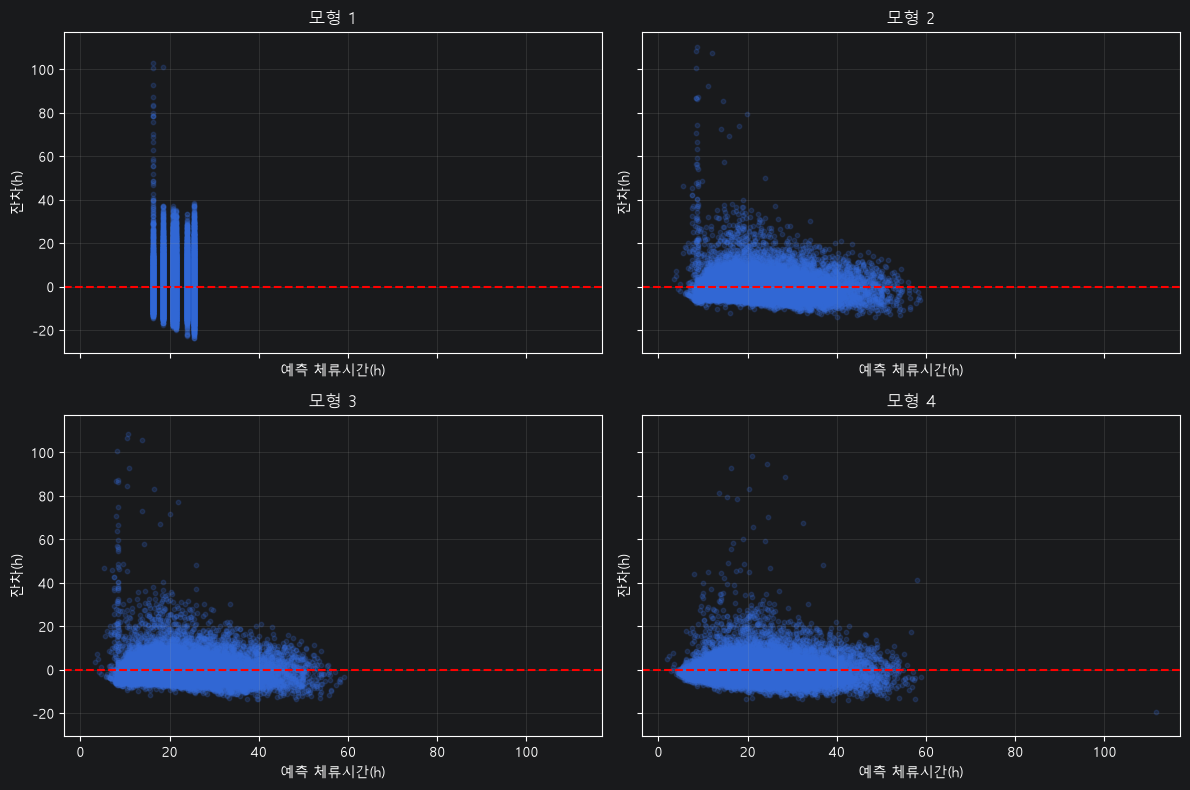

In [53]:
import matplotlib.pyplot as plt

# 한글 표시
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True,
)

for ax, (name, model) in zip(axes.ravel(), models.items()):

    ax.scatter(
        model.fittedvalues,   # 예측값
        model.resid,          # 잔차 = 실제값 - 예측값
        s=10,
        alpha=0.2,
    )

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("예측 체류시간(h)")
    ax.set_ylabel("잔차(h)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

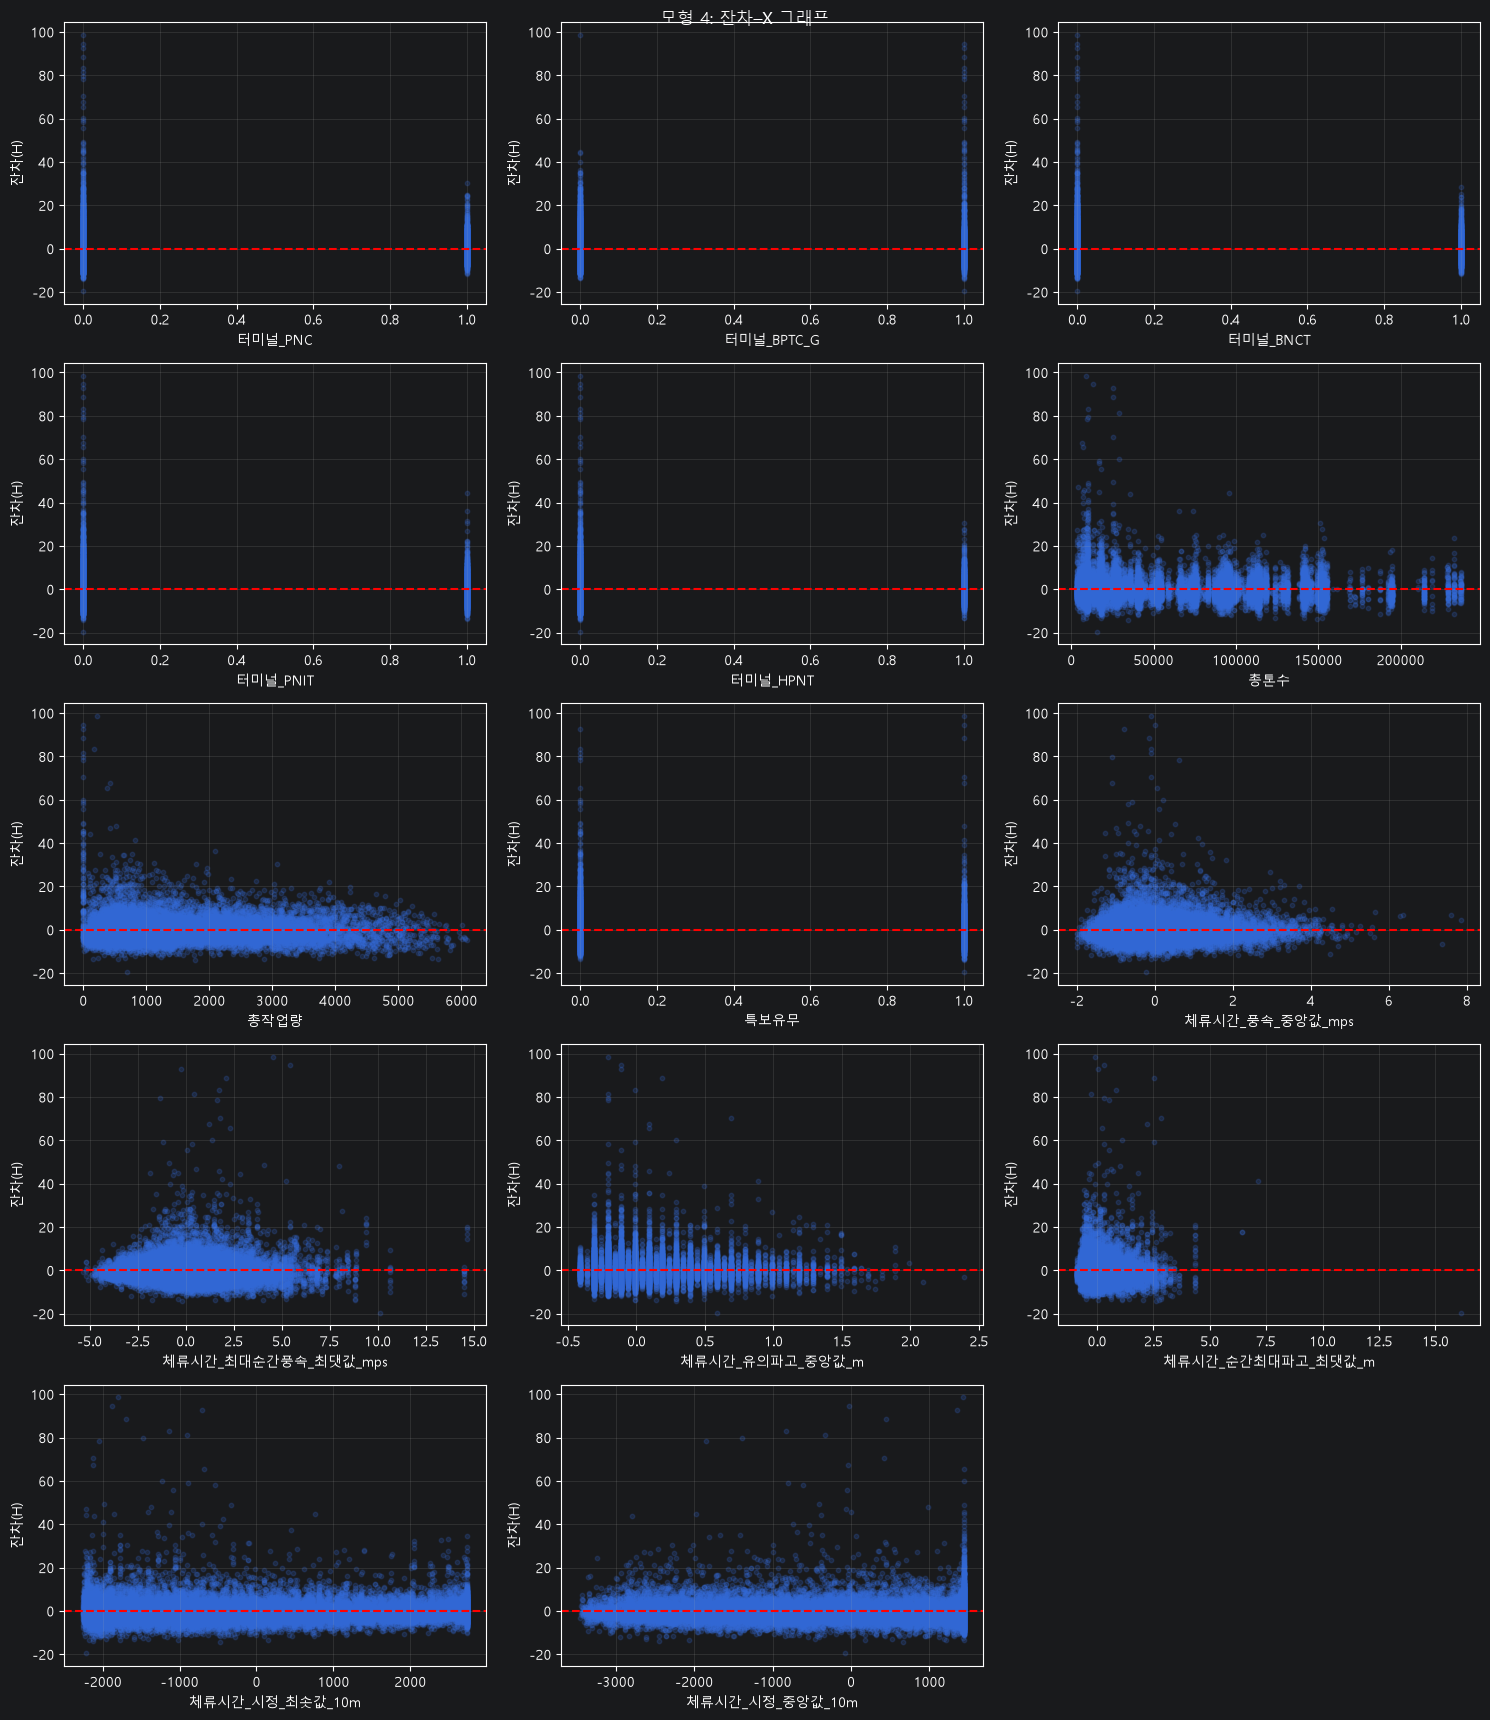

In [54]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 다른 모형을 보려면 "모형 4"를 변경
model_name = "모형 4"
model = models[model_name]

# 절편과 상호작용항을 제외한 독립변수
x_cols = [
    col for col in model.model.exog_names
    if col != "const" and ":" not in col
]

rows = (len(x_cols) + 2) // 3

fig, axes = plt.subplots(
    rows, 3,
    figsize=(15, rows * 3.5),
    squeeze=False,
)

for ax, col in zip(axes.ravel(), x_cols):
    ax.scatter(
        data.loc[model.resid.index, col],
        model.resid,
        s=10,
        alpha=0.2,
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel(col)
    ax.set_ylabel("잔차(H)")
    ax.grid(alpha=0.2)

# 남는 그래프 칸 숨기기
for ax in axes.ravel()[len(x_cols):]:
    ax.set_visible(False)

fig.suptitle(f"{model_name}: 잔차–X 그래프")
plt.tight_layout()
plt.show()